# Manutenção Preditiva com Machine Learning

**Problema:** Prever quebras e falhas para minimizar as paradas.

**Alvo:** falha_maquina, onde 1 significa falha e 0 significa operação normal.

**Comparação:** KNN e Árvore de Decisão.

## Fase 1: Análise Exploratória (EDA)

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from imblearn.under_sampling import RandomUnderSampler

In [ ]:
df = pd.read_csv('data/manutencao_preditiva.csv')
df.head()

In [4]:
# Ver quantas linhas e colunas existem
print("Total de linhas e colunas:")
print(df.shape)

# Ver os tipos das colunas (números, textos)
print("\nTipos de dados:")
print(df.dtypes)

# Resumo com médias, mínimos e máximos de cada coluna
print("\nResumo:")
df.describe()

Total de linhas e colunas:
(10000, 14)

Tipos de dados:
udi                          int64
id_produto                  object
tipo                        object
temperatura_ar_k           float64
temperatura_processo_k     float64
velocidade_rotacao_rpm     float64
torque_nm                  float64
desgaste_ferramenta_min      int64
falha_maquina                int64
falha_twf                    int64
falha_hdf                    int64
falha_pwf                    int64
falha_osf                    int64
falha_rnf                    int64
dtype: object

Resumo:


,udi,temperatura_ar_k,temperatura_processo_k,velocidade_rotacao_rpm,torque_nm,desgaste_ferramenta_min,falha_maquina,falha_twf,falha_hdf,falha_pwf,falha_osf,falha_rnf
count,10000.00000,9500.000000,9500.000000,9500.000000,9500.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000
mean,5000.50000,300.002158,310.000895,1539.245263,39.974168,107.951000,0.033900,0.004600,0.011500,0.009500,0.009800,0.00190
std,2886.89568,2.001689,1.486432,180.273589,9.995453,63.654147,0.180981,0.067671,0.106625,0.097009,0.098514,0.04355
min,1.00000,295.300000,305.700000,1168.000000,3.800000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
25%,2500.75000,298.300000,308.800000,1423.000000,33.100000,53.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
50%,5000.50000,300.100000,310.100000,1504.000000,40.100000,108.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
75%,7500.25000,301.500000,311.100000,1613.000000,46.700000,162.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
max,10000.00000,304.500000,313.800000,2886.000000,76.600000,253.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.00000


In [13]:
print(df['falha_maquina'].value_counts())
df['falha_maquina'].value_counts(normalize=True)


falha_maquina
0    9661
1     339
Name: count, dtype: int64


falha_maquina
0    0.9661
1    0.0339
Name: proportion, dtype: float64

### 1.2 Gráficos analíticos

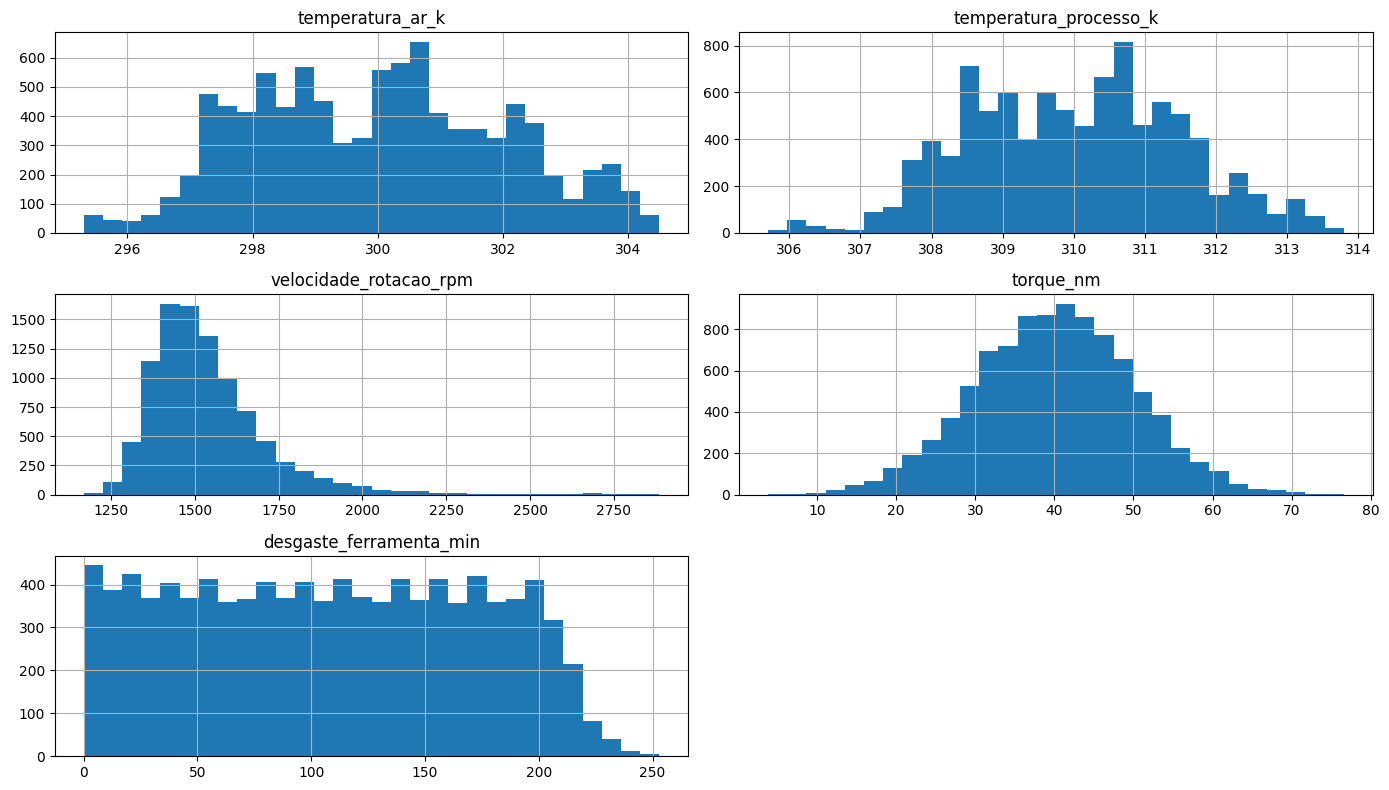

In [ ]:
lista_sensores = ['temperatura_ar_k', 'temperatura_processo_k', 'velocidade_rotacao_rpm', 'torque_nm', 'desgaste_ferramenta_min']

df[lista_sensores].hist(bins=30, figsize=(14, 8))
plt.suptitle('Distribuição dos sensores')
plt.tight_layout()
plt.show()